# Par yields de la zone euro via l'API de la BCE (SDMX)

La FRED ne publie pas les par yields de la zone euro. La source officielle est le **Data Portal de la BCE**, dataset `YC` (courbe des rendements de la zone euro, estimee par la BCE a partir des obligations d'Etat).

Cle de serie : `YC.B.U2.EUR.4F.G_N_A.SV_C_YM.PY_<maturite>`

- `G_N_A` : obligations d'Etat notees AAA ; `G_N_C` : toutes obligations d'Etat de la zone euro
- `PY_` : par yield (`SR_` = taux spot, `IF_` = taux forward instantane)
- maturite : `3M`, `1Y`, `2Y`, `5Y`, `10Y`, `30Y`...

Aucune cle API n'est necessaire.

Liens :
- Portail : https://data.ecb.europa.eu/data/data-categories/financial-markets-and-interest-rates/euro-area-yield-curves
- Par yield 10 ans (AAA) : https://data.ecb.europa.eu/data/datasets/YC/YC.B.U2.EUR.4F.G_N_A.SV_C_YM.PY_10Y
- Par yield 10 ans (toutes notes) : https://data.ecb.europa.eu/data/datasets/YC/YC.B.U2.EUR.4F.G_N_C.SV_C_YM.PY_10Y
- Documentation de l'API : https://data.ecb.europa.eu/help/api/data

In [1]:
# !pip install pandas numpy matplotlib requests

In [2]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

BASE = 'https://data-api.ecb.europa.eu/service/data'
RATING = 'G_N_A'        # 'G_N_A' = AAA ; 'G_N_C' = toutes obligations d'Etat
START = '2004-09-06'    # debut de la courbe BCE

SHORT = ['3M', '6M', '9M', '1Y', '2Y']
LONG = ['5Y', '7Y', '10Y', '15Y', '20Y', '30Y']

plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.grid'] = True

In [3]:
def ecb_series(key, start=START, end=None):
    """Telecharge une serie SDMX de la BCE et renvoie une pd.Series datee (en %)."""
    params = {'format': 'csvdata', 'startPeriod': start}
    if end:
        params['endPeriod'] = end
    r = requests.get(f'{BASE}/{key}', params=params, timeout=60)
    if r.status_code == 404:
        return None            # maturite non publiee
    r.raise_for_status()
    d = pd.read_csv(io.StringIO(r.text))
    s = pd.Series(d['OBS_VALUE'].values, index=pd.to_datetime(d['TIME_PERIOD']))
    return s.sort_index()

def par_yield_key(maturity, rating=RATING):
    return f'YC/B.U2.EUR.4F.{rating}.SV_C_YM.PY_{maturity}'

curves = {}
for m in SHORT + LONG:
    try:
        s = ecb_series(par_yield_key(m))
    except Exception as exc:
        print(f'Echec {m} : {exc}')
        continue
    if s is None:
        print(f'Serie absente pour {m}, ignoree')
    else:
        curves[m] = s

df = pd.DataFrame(curves)
df.index.name = 'date'
print('Maturites chargees :', list(df.columns))
df.tail()

Echec 6M : 500 Server Error: Internal Server Error for url: https://data-api.ecb.europa.eu/service/data/YC/B.U2.EUR.4F.G_N_A.SV_C_YM.PY_6M?format=csvdata&startPeriod=2004-09-06
Echec 9M : HTTPSConnectionPool(host='data-api.ecb.europa.eu', port=443): Read timed out. (read timeout=60)
Echec 2Y : 500 Server Error: Internal Server Error for url: https://data-api.ecb.europa.eu/service/data/YC/B.U2.EUR.4F.G_N_A.SV_C_YM.PY_2Y?format=csvdata&startPeriod=2004-09-06
Maturites chargees : ['3M', '1Y', '5Y', '7Y', '10Y', '15Y', '20Y', '30Y']


,3M,1Y,5Y,7Y,10Y,15Y,20Y,30Y
date,,,,,,,,
2026-09-29,2.524294,2.985873,3.342617,3.432269,3.576265,3.744967,3.816886,3.798743
2026-09-30,2.500221,2.958642,3.284411,3.388321,3.547427,3.725700,3.798912,3.777258
2026-10-01,2.507180,2.919741,3.260474,3.380839,3.554055,3.742414,3.819257,3.799329
2026-10-02,2.520919,2.863635,3.125544,3.251662,3.427144,3.614302,3.691845,3.678804
2026-10-05,2.530283,2.851017,3.159032,3.287053,3.463841,3.654453,3.735627,3.728187


## 1. Evolution des par yields : court terme vs long terme

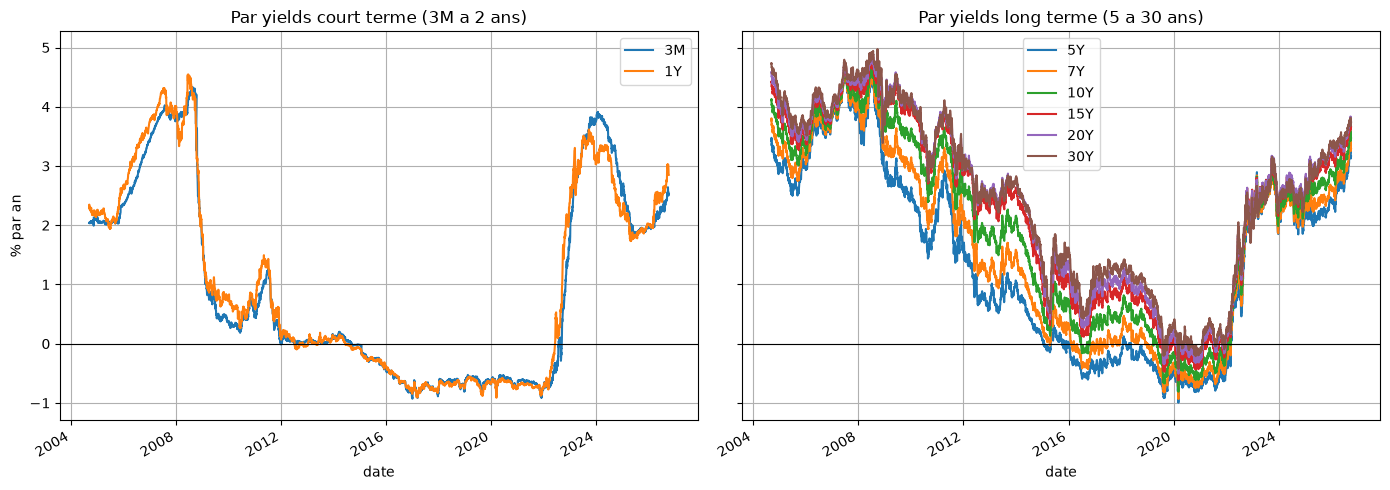

In [4]:
short_cols = [m for m in SHORT if m in df]
long_cols = [m for m in LONG if m in df]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
df[short_cols].plot(ax=axes[0], title='Par yields court terme (3M a 2 ans)')
df[long_cols].plot(ax=axes[1], title='Par yields long terme (5 a 30 ans)')
for ax in axes:
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_ylabel('% par an')
plt.tight_layout()
plt.show()

## 2. Courbe des par yields a une date donnee

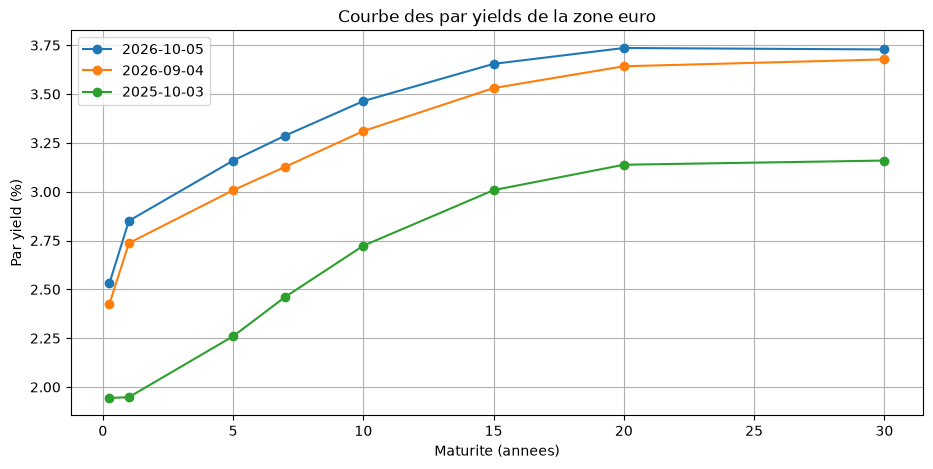

In [5]:
ORDER = {'3M': .25, '6M': .5, '9M': .75}
def to_years(m):
    return ORDER[m] if m in ORDER else float(m[:-1])

last = df.index[-1]
dates = [last, last - pd.DateOffset(months=1), last - pd.DateOffset(years=1)]

fig, ax = plt.subplots()
for d in dates:
    row = df.loc[:d].iloc[-1].dropna()
    ax.plot([to_years(m) for m in row.index], row.values, marker='o',
            label=f'{df.loc[:d].index[-1]:%Y-%m-%d}')
ax.set_xlabel('Maturite (annees)')
ax.set_ylabel('Par yield (%)')
ax.set_title('Courbe des par yields de la zone euro')
ax.legend()
plt.show()

## 3. Pentes de la courbe et inversions

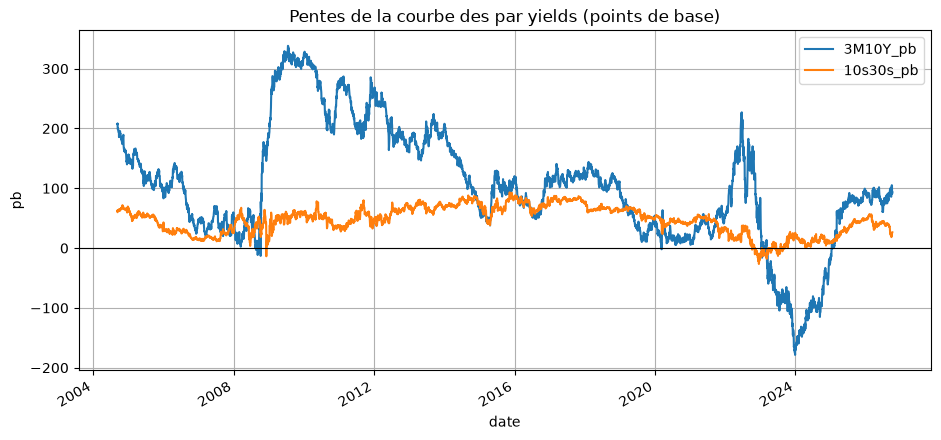

3M10Y_pb : inversee 9.0% du temps, derniere valeur 93 pb
10s30s_pb : inversee 3.0% du temps, derniere valeur 26 pb


In [6]:
slopes = pd.DataFrame(index=df.index)
if {'2Y', '10Y'} <= set(df):
    slopes['2s10s_pb'] = (df['10Y'] - df['2Y']) * 100
if {'3M', '10Y'} <= set(df):
    slopes['3M10Y_pb'] = (df['10Y'] - df['3M']) * 100
if {'10Y', '30Y'} <= set(df):
    slopes['10s30s_pb'] = (df['30Y'] - df['10Y']) * 100

ax = slopes.plot()
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Pentes de la courbe des par yields (points de base)')
ax.set_ylabel('pb')
plt.show()

for c in slopes:
    inv = (slopes[c].dropna() < 0).mean()
    print(f'{c} : inversee {inv:.1%} du temps, derniere valeur {slopes[c].dropna().iloc[-1]:.0f} pb')

## 4. Statistiques et correlations des variations quotidiennes

In [7]:
print(df.describe().T.round(2))
changes_bp = df.diff().dropna(how='all') * 100
print()
print('Volatilite annualisee des variations (pb) :')
print((changes_bp.std() * np.sqrt(252)).round(0))
print()
print(changes_bp.corr().round(2))

      count  mean   std   min   25%   50%   75%   max
3M   5646.0  0.95  1.61 -0.93 -0.57  0.29  2.21  4.33
1Y   5646.0  1.01  1.62 -0.91 -0.59  0.50  2.35  4.54
5Y   5646.0  1.44  1.55 -1.00 -0.14  1.67  2.66  4.74
7Y   5646.0  1.70  1.53 -0.93  0.12  2.06  2.96  4.74
10Y  5646.0  1.99  1.52 -0.81  0.46  2.33  3.33  4.78
15Y  5646.0  2.27  1.50 -0.62  0.83  2.53  3.59  4.84
20Y  5646.0  2.40  1.48 -0.51  1.02  2.63  3.69  4.89
30Y  5646.0  2.46  1.44 -0.42  1.20  2.57  3.75  4.97

Volatilite annualisee des variations (pb) :
3M     44.0
1Y     44.0
5Y     65.0
7Y     64.0
10Y    64.0
15Y    65.0
20Y    66.0
30Y    69.0
dtype: float64

       3M    1Y    5Y    7Y   10Y   15Y   20Y   30Y
3M   1.00  0.35  0.11  0.10  0.10  0.09  0.08  0.09
1Y   0.35  1.00  0.72  0.66  0.60  0.54  0.50  0.45
5Y   0.11  0.72  1.00  0.98  0.92  0.84  0.79  0.73
7Y   0.10  0.66  0.98  1.00  0.98  0.91  0.87  0.80
10Y  0.10  0.60  0.92  0.98  1.00  0.98  0.94  0.86
15Y  0.09  0.54  0.84  0.91  0.98  1.00  0.99

## 5. Comparaison AAA vs toutes obligations d'Etat (10 ans)

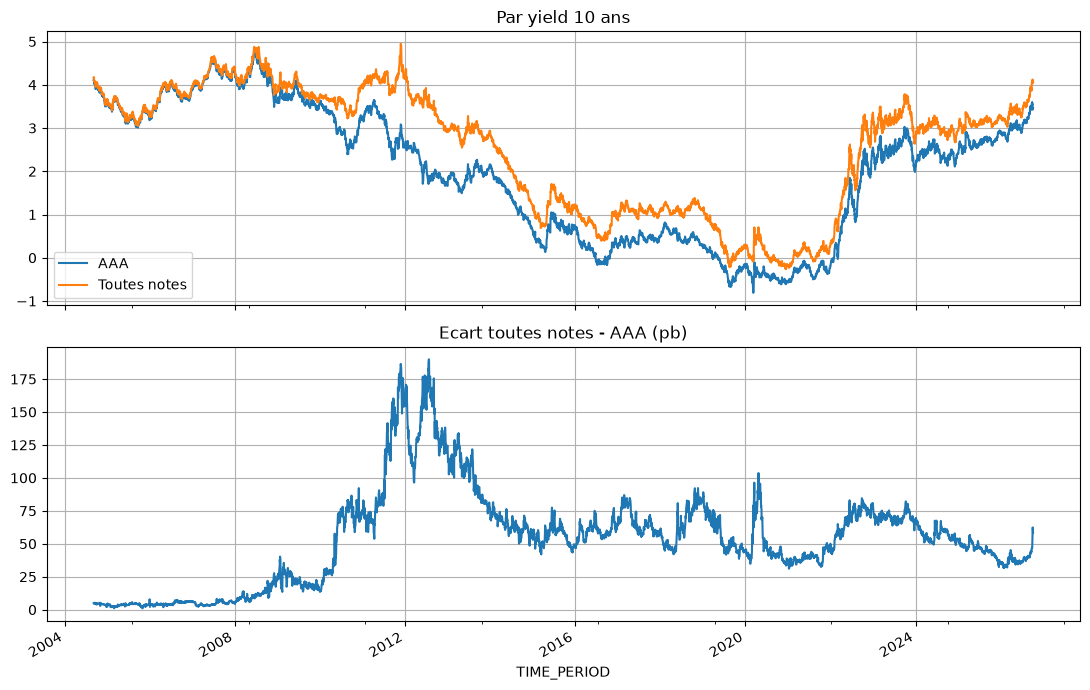

In [8]:
aaa = ecb_series(par_yield_key('10Y', 'G_N_A'))
allc = ecb_series(par_yield_key('10Y', 'G_N_C'))
if aaa is not None and allc is not None:
    cmp_ = pd.DataFrame({'AAA': aaa, 'Toutes notes': allc}).dropna()
    cmp_['Prime de credit (pb)'] = (cmp_['Toutes notes'] - cmp_['AAA']) * 100
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    cmp_[['AAA', 'Toutes notes']].plot(ax=axes[0], title='Par yield 10 ans')
    cmp_['Prime de credit (pb)'].plot(ax=axes[1], title='Ecart toutes notes - AAA (pb)')
    plt.tight_layout()
    plt.show()

## 6. Export

In [9]:
df.to_csv('euro_par_yields_ecb.csv')
slopes.to_csv('euro_par_yield_slopes.csv')
print('Fichiers ecrits : euro_par_yields_ecb.csv, euro_par_yield_slopes.csv')

Fichiers ecrits : euro_par_yields_ecb.csv, euro_par_yield_slopes.csv
